## Assignment 02: Fitting and Alignment

**Index No:** 230186E  
**Name:** Fernando W. H. D.  
**GitHub:** https://github.com/himashafdo/EN3160-A02.git

In [33]:
# libraries I used
import numpy as np
import matplotlib.pyplot as plt, glob, os
from PIL import Image
import cv2 as cv
from scipy.ndimage import maximum_filter

# Question 01


In [3]:
def drop_clusters(blobs):
    """
    I defined this function to drop clusters of blobs that are too close to each other."""
    out = []
    for b in blobs:
        n = sum(1 for o in blobs
                if o is not b and o[2] < b[2] and np.hypot(o[0]-b[0], o[1]-b[1]) < b[2])
                #it does this by checking if the distance between the two blobs is less than the radius of the bigger blob
        if n < 2:
            out.append(b)
    return out

sigma range: 10 - 40, number of scales: 50
Number of detected blobs: 34
largest 5 blobs (x, y, radius, sigma):
  (193, 185, 18.47, 13.06)
  (197, 45, 16.74, 11.84)
  (287, 64, 16.74, 11.84)
  (226, 359, 15.01, 10.61)
  (262, 276, 15.01, 10.61)


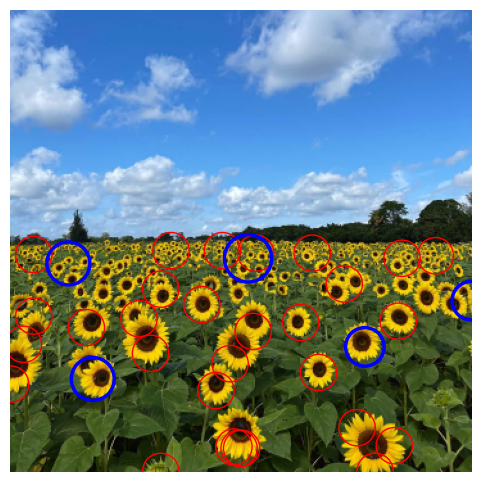

In [4]:
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
b, g, r = [im[:,:,k].astype(np.float32)/255 for k in range(3)]
gray = np.clip(r-b, 0, 1) # did this to enhance sunflowers in the image and surpress clouds


sigma_min = 10; sigma_max = 40; n_scales = 50; 
sigmas = np.linspace(sigma_min, sigma_max, n_scales)
stack = []

for s in sigmas:
    g = cv.GaussianBlur(gray, (0, 0), s)
    stack.append((s**2) * cv.Laplacian(g, cv.CV_32F)) #since LoG is sigma^2 * Laplacian(Gaussian)

stack = np.stack(stack)
resp = -stack #as from before all dark blobs are now clouds due to plane substraction I chose bright blobs

thr = 0.25*resp.max()
nms = (resp == maximum_filter(resp, size=(3, 3, 3))) & (resp >= thr)
si, xs, ys = np.nonzero(nms)

blobs = [(xs_, ys_, np.sqrt(2)*sigmas[i], sigmas[i], resp[i, xs_, ys_])
         for i, xs_, ys_ in zip(si, xs, ys)]

blobs = drop_clusters(blobs)
blobs.sort(key=lambda b: -b[2])

print(f"sigma range: {sigma_min} - {sigma_max}, number of scales: {n_scales}")
print(f"Number of detected blobs: {len(blobs)}")
print("largest 5 blobs (x, y, radius, sigma):")
for x, y, r, s, _ in blobs[:5]:
    print(f"  ({x}, {y}, {r:.2f}, {s:.2f})")

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))

for x, y, r, s, *_ in blobs:
    ax.add_patch(plt.Circle((y, x), r, color='red', fill=False, lw=1))

for x, y, r, s, *_ in blobs[:5]: #top 5
    ax.add_patch(plt.Circle((y, x), r, color='blue', fill=False, lw=2.5))

ax.axis('off'); plt.show()


### Intepretation and Disscussion

Substracting the blue from red made yellow petals bright and the sky and white clouds dark. Through that I was able to remove the false detections that was cluttering the output (I assumed the requirement to detect only sunflowers(petals + brown head) as blobs) when I used just the grayscale input.

We can clearly see that the flowers in the foreground are identified perfectly as blobs while the ones in the background are bunched up, this is because the high minimum sigma values which I had to use to select the brown heads of the flowers as well.

One limitaition is that several of the largest circles (blue) are not single flowers. They sit on groups of small, distant flowers that merge into one bright patch at larger σ, so LoG treats the group as one blob. But couple are still detecting a whole flowers which are in the foreground.


## Question 02


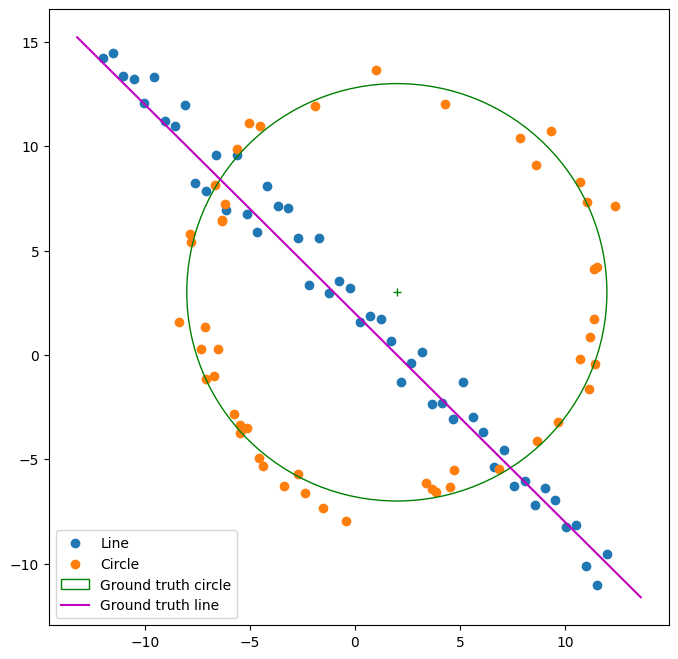

In [13]:
# Generation of a Noisy Point Set Conforming to a Line and a Circle
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt

np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt , y0_gt = 2 , 3 # Center
s = r /16
t = np . random . uniform (0 , 2*np . pi , half_n )
n = s*np . random . randn ( half_n )
x , y = x0_gt + ( r + n)*np . cos ( t ) , y0_gt + ( r + n)*np . sin ( t )
X_circ = np . hstack ( ( x . reshape ( half_n , 1 ) , y . reshape ( half_n , 1 ) ) )
s = 1.
m, b = -1, 2
x = np . linspace (-12, 12 , half_n )
y = m*x + b + s*np . random . randn ( half_n )
X_line = np.hstack ( ( x . reshape ( half_n , 1 ) , y . reshape ( half_n , 1 ) ) )
X = np.vstack ( ( X_circ , X_line ) ) # All points

fig , ax = plt.subplots (1 ,1 , figsize=(8 ,8))
ax.scatter ( X_line [ : , 0 ] , X_line [ : , 1 ] , label='Line' )
ax.scatter ( X_circ [ : , 0 ] , X_circ [ : , 1 ] , label='Circle' )
circle_gt = plt.Circle( ( x0_gt , y0_gt ) , r , color= 'g' , fill =False , label='Ground truth circle' )
ax.add_patch ( circle_gt )
ax.plot ( ( x0_gt ) , ( y0_gt ) , '+' , color= 'g' )
x_min , x_max = ax . get_xlim ( )
x_ = np . array ( [ x_min , x_max ] )
y_ = m*x_ + b
plt . plot ( x_ , y_ , color= 'm' , label= 'Ground truth line')
plt . legend ( )

In [17]:
#--(a)--
rng = np.random.default_rng()

def line_from_2pts(p,q):
    dv=p-q
    n=np.array([-dv[1],dv[0]])/ np.linalg.norm(dv)
    return n, np.dot(n,p)

def line_err(X,n,d):
    return np.abs(X @ n - d)

def fit_line_tls(P):
    c = P.mean(0)
    n=np.linalg.svd(P-c)[2][-1]
    return n, np.dot(n,c)

def ransac_line(X, t, min_inl, iters=500):
    best = None
    for _ in range(iters):
        i,j = rng.choice(len(X), size=2, replace=False)
        n,d = line_from_2pts(X[i],X[j])
        inl = line_err(X,n,d)<t
        if inl.sum()>=min_inl and (best is None or inl.sum()>best['inl'].sum()):
            best = dict(inl=inl, sample=(i,j), n=n, d=d)
    return best

t_line, min_line = 1.5, 35
L = ransac_line(X, t_line, min_line)
n_ref, d_ref = fit_line_tls(X[L['inl']])

print("best-sample line (a, b, d):", L['n'], L['d'])
print("refit line (a, b, d):", n_ref, d_ref, "| inliers:", L['inl'].sum())

best-sample line (a, b, d): [-0.69877621 -0.71534035] -1.6715573974282973
refit line (a, b, d): [0.71564883 0.69846028] 1.5617747756951446 | inliers: 57


#### Discussion

*Parameter choice.* Noise (σ = 1) is added to the y coordinate of the line points, so the normal distance to the true line has σ = 1/√2 ≈ 0.71. A threshold of 1.5 (about 2.1σ) keeps about 96% of true line points, roughly 48 of 50, while rejecting most points that are not near the line. The minimum consensus was set to 35, safely below the expected count but far above what a random line through the circle points would collect.

*Result (seed 0).* The best-sample line was n = [0.699, 0.715], d = 1.672 (sign flipped from the computed normal to compare with the refit). The TLS refit on its 57 inliers gave n = [0.716, 0.698], d = 1.562. The ground truth y = −x + 2 has n = [0.707, 0.707], d = 1.414. The refit is closer in d (error 0.15 versus 0.26), because two noisy points give an unreliable line while TLS averages over all inliers. The 57 inliers exceed the 50 line points, so at least 7 circle points lie within the threshold where the circle crosses the line. They are removed before the circle fit.


In [20]:
#---(b)---
def circle_from_3pts(p1,p2,p3):
    A = 2* np.array([p2-p1, p3-p1])
    b_ = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(A)) < 1e-10:
        return None
    c = np.linalg.solve(A, b_)
    r = np.linalg.norm(c - p1)
    return c, r

def circle_err(X, c, r):
    return np.abs(np.linalg.norm(X - c, axis=1) - r)

def ransac_circle(X, t, min_inl, iters=500):
    best = None
    for _ in range(iters):
        idx = rng.choice(len(X), size=3, replace=False)
        out = circle_from_3pts(X[idx[0]], X[idx[1]], X[idx[2]])
        if out is None:
            continue
        c,r_  = out
        inl = circle_err(X,c,r_)<t
        if inl.sum()>=min_inl and (best is None or inl.sum()>best['inl'].sum()):
            best = dict(inl=inl, sample=idx, c=c, r=r_)
    return best

def fit_circle(P, c0, r0):
    f = lambda q: np.sum((np.linalg.norm(P-q[:2], axis=1)-q[2])**2)
    res = minimize(f, [*c0, r0])
    return res.x[:2], res.x[2]

X_rem = X[~L['inl']]
t_circ, min_circ = 1.25, 25
C = ransac_circle(X_rem, t_circ, min_circ)
c_ref, r_ref = fit_circle(X_rem[C['inl']], C['c'], C['r'])

print("remnant points:", len(X_rem))
print("best-sample circle (cx, cy, r):", C['c'], C['r'])
print("refit circle (cx, cy, r):", c_ref, r_ref, "| inliers:", C['inl'].sum())
print("ground truth: (2, 3), r = 10")

remnant points: 43
best-sample circle (cx, cy, r): [2.02870779 3.09086218] 10.117431786696262
refit circle (cx, cy, r): [1.86958999 3.06549698] 9.949292535404615 | inliers: 43
ground truth: (2, 3), r = 10


#### Discussion

*Parameter choice.* The radial noise is σ = r/16 = 0.625, so a threshold of 1.25 (2σ) keeps about 95% of true circle points. At most 50 circle points remain after the line inliers are removed, so a minimum consensus of 25 is well above chance and below the expected count.

*Result (seed 0).* 43 points remained after the line inliers were removed. The best-sample circle was centre (2.03, 3.09), r = 10.12. The refit on the inliers (all 43 remnant points) gave centre (1.87, 3.07), r = 9.95. The ground truth is centre (2, 3), r = 10. The refit radius error is 0.05 (versus 0.12), but the centre error is 0.15 (versus 0.10), so the three-point circle happened to land slightly closer in centre for this seed. The refit is still the more reliable estimate in general, because it averages 43 points instead of depending on three noisy ones.

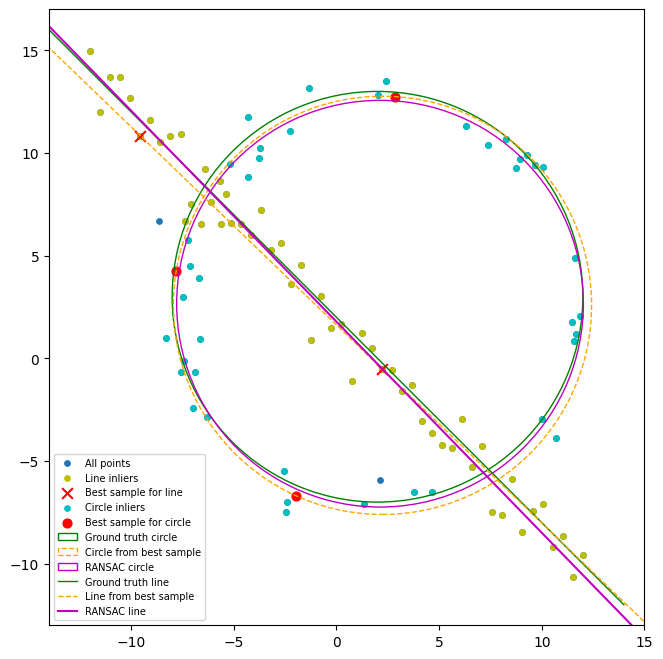

In [8]:
#---(c)---
def draw_line(ax, n, d, **kw):
    p0, dv = n * d, np.array([-n[1], n[0]])
    q = np.array([p0 - 25 * dv, p0 + 25 * dv])
    ax.plot(q[:, 0], q[:, 1], **kw)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, c='tab:blue', s=15, label='All points')
ax.scatter(*X[L['inl']].T, c='y', s=15, label='Line inliers')
ax.scatter(*X[list(L['sample'])].T, c='r', marker='x', s=60, label='Best sample for line')
ax.scatter(*X_rem[C['inl']].T, c='c', s=15, label='Circle inliers')
ax.scatter(*X_rem[C['sample']].T, c='r', s=40, label='Best sample for circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.add_patch(plt.Circle(C['c'], C['r'], color='orange', fill=False, ls='--', label='Circle from best sample'))
ax.add_patch(plt.Circle(c_ref, r_ref, color='m', fill=False, label='RANSAC circle'))
xs_ = np.array([-14, 14])
ax.plot(xs_, m * xs_ + b, 'g', lw=1, label='Ground truth line')
draw_line(ax, L['n'], L['d'], color='orange', ls='--', lw=1, label='Line from best sample')
draw_line(ax, n_ref, d_ref, color='m', label='RANSAC line')
ax.set_xlim(-14, 15); ax.set_ylim(-13, 17)
ax.set_aspect('equal'); ax.legend(fontsize=7); plt.show()

### (d) Fitting the circle first

Fitting the circle first is unreliable. A circle has three parameters and can approximate a line over a segment: three points taken from the line define a very large, nearly straight circle that passes through most of the line points. Its consensus can therefore be comparable to that of the true circle, so RANSAC may return this useless "circle". Even when the true circle wins, its consensus band also contains the line points that cross the circle, which pull the refit away from the true circle and are then removed from the line's data.

Fitting the line first is more robust. The line is the simpler model (two parameters, two-point samples), so a random sample is more likely to be all inliers, and the circle points curve away from the line so they do not form a competing consensus. After its inliers are removed, the remaining points are mostly circle points. In general, the most constrained model should be fitted first, and the more flexible one on the remnant.

## Question 03

In [ ]:
dst_pts=[]

def select_points(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(dst_pts) < 4:
        dst_pts.append([x, y])
        # print(f"Point {len(dst_pts)} selected: ({x}, {y})") #removed to reduce clutter

def overlay_flag(target_path, flag_path, output_path):
    global dst_pts
    dst_pts = []

    target_img = cv.imread(target_path)
    flag_img = cv.imread(flag_path)

    tem_img = target_img.copy()
    cv.namedWindow("Select 4 points on planar surface", cv.WINDOW_NORMAL)
    cv.setMouseCallback("Select 4 points on planar surface", select_points)

    while len(dst_pts) < 4:
        cv.imshow("Select 4 points on planar surface", tem_img)
        if cv.waitKey(1) & 0xFF == 27:  # Exit on ESC key
            break
    cv.destroyAllWindows()

    if len(dst_pts) < 4:
        print("Not enough points selected")
        return

    h_flag, w_flag = flag_img.shape[:2]
    src_pts = np.float32([
        [0, 0], 
        [w_flag - 1, 0], 
        [w_flag - 1, h_flag - 1], 
        [0, h_flag - 1]
    ])

    dst_pts_np = np.float32(dst_pts)

    H, _ = cv.findHomography(src_pts, dst_pts_np)
    h_target, w_target = target_img.shape[:2]
    warped_flag = cv.warpPerspective(flag_img, H, (w_target, h_target))

    mask = np.zeros((h_target, w_target), dtype=np.uint8)
    cv.fillConvexPoly(mask, dst_pts_np.astype(int), 255)

    result = target_img.copy()

    bg_region = target_img[mask == 255].astype(float) / 255.0
    flag_region = warped_flag[mask == 255].astype(float) / 255.0

    multiply_layer = bg_region * flag_region #added because some of the flags are transparent and I wanted to keep the background visible
    blend_factor = 0.4  
    final_region = (blend_factor * flag_region + (1 - blend_factor) * multiply_layer) * 255.0

    result[mask == 255] = np.clip(final_region, 0, 255).astype(np.uint8)

    cv.imwrite(output_path, result)
    cv.imshow("Result", result)
    cv.waitKey(0)
    cv.destroyAllWindows()

#overlay_flag('a2images\\wadham.jpg', 'a2images\\flag.png', 'results\\q3_result_1.jpg')
#overlay_flag('a2images\\parliment.jpg', 'a2images\\sri_lanka.webp', 'results\\q3_result_2.jpg')
#overlay_flag('a2images\\messi.jpg', 'a2images\\argentina.webp', 'results\\q3_result_3.jpg')
#overlay_flag('a2images\\entc_building.jpg', 'a2images\\entc.png', 'results\\q3_result_4.jpg')
#overlay_flag('a2images\\flood.jpg', 'a2images\\superman.jpg', 'results\\q3_result_5.jpg')



### Discussion

Homography estimation: Selecting 4 points on the target planar surface provides 8 linear constraints to solve for the 8 degrees of freedom of the $3 \times 3$ matrix $H$ via cv2.findHomography. cv2.warpPerspective uses inverse mapping with bilinear interpolation to avoid sampling gaps in the warped overlay.

Blending parameter choice: Direct replacement produced a flat look. Pure multiply blending ($I_{\text{bg}} \times I_{\text{overlay}} / 255$) preserves stone texture and shadows, but turns white areas ($255$) completely transparent. A hybrid weight of $\alpha = 0.4$ ($0.4 \cdot I_{\text{overlay}} + 0.6 \cdot I_{\text{multiply}}$) was chosen to keep white colors visible while retaining underlying wall texture.

Results & choice of image pairs: The hybrid blend successfully retains building details (like windows and masonry lines) through the superimposed graphics. The image pairs were chosen to simulate practical planar mapping: (1) mounting institutional crests/flags onto historical stone facades for ceremonial events, and (2) projecting artwork onto urban structures to prototype public street installations

## Question 04

AAAA1.jpg: good matches 24, RANSAC inliers 9


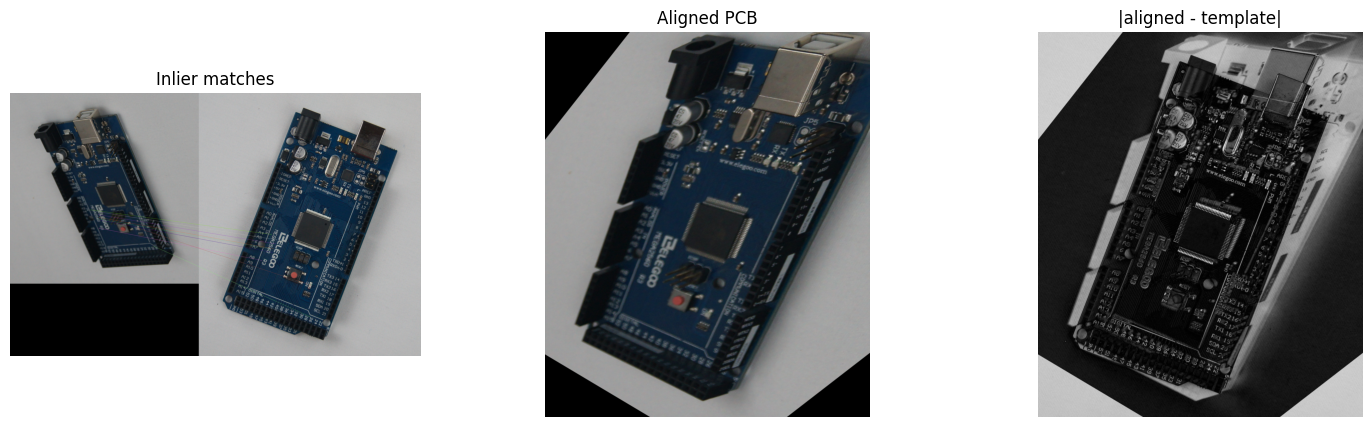

ADAD1.jpg: good matches 217, RANSAC inliers 158


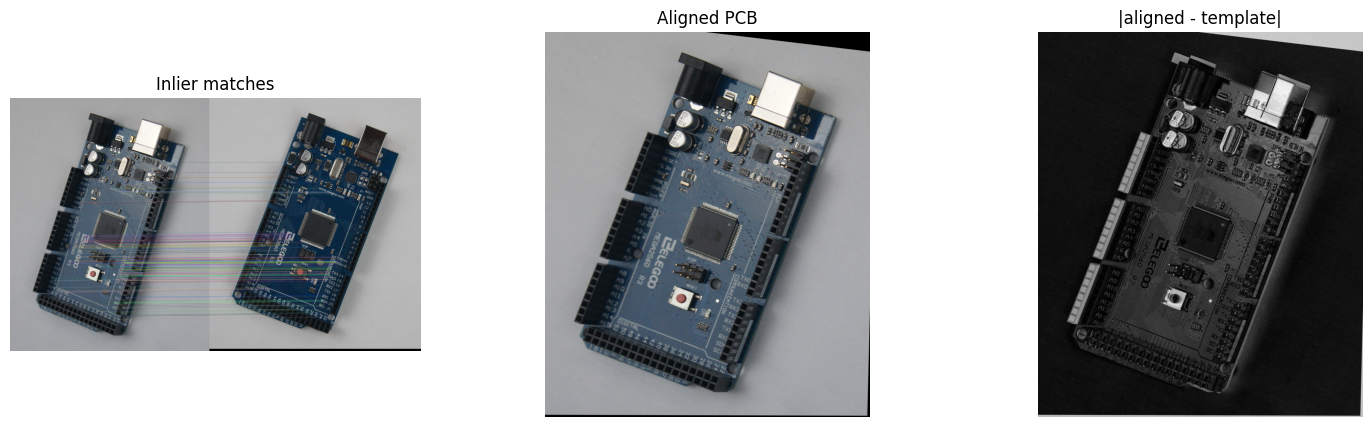

AECC2.jpg: good matches 3760, RANSAC inliers 3565


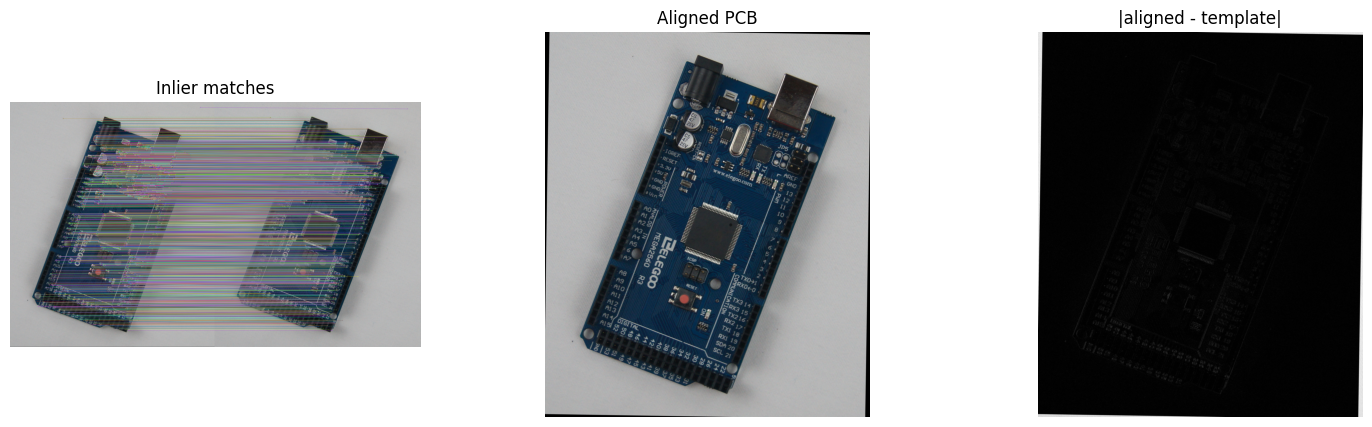

AECC3.jpg: good matches 4882, RANSAC inliers 4638


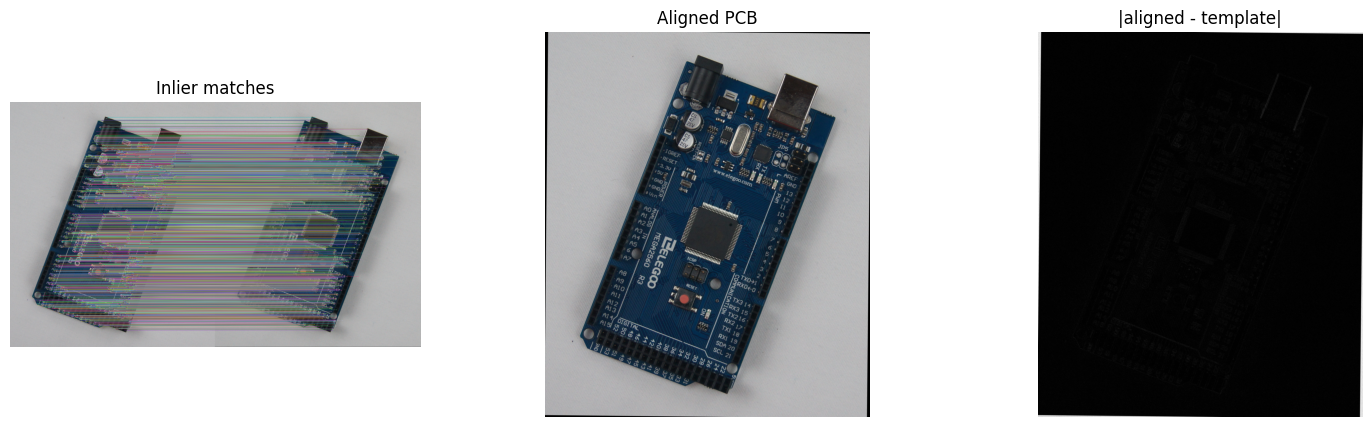

AECC4.jpg: good matches 3272, RANSAC inliers 3118


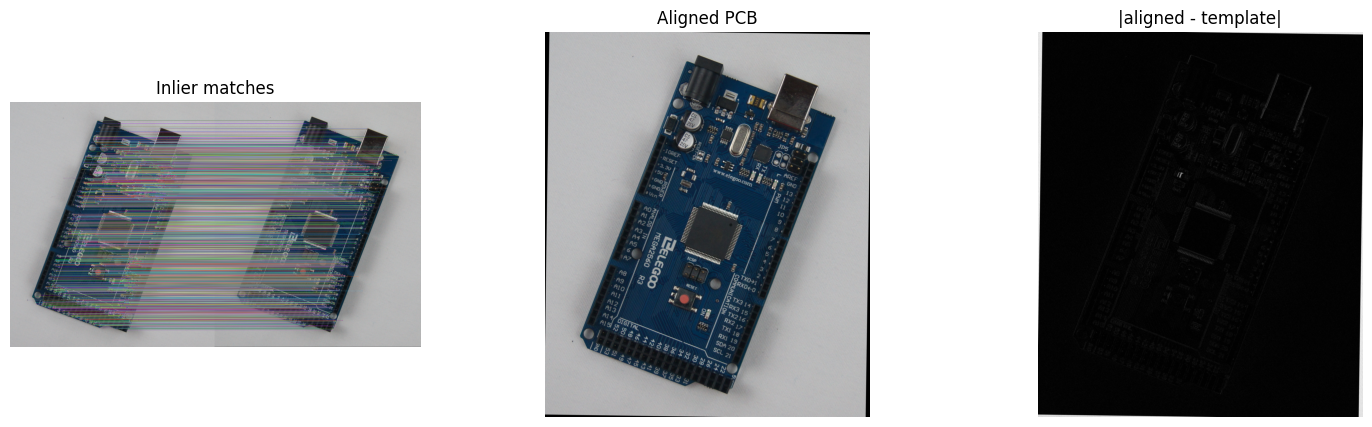

In [ ]:
tmpl = cv.imread('a2images\\pcbs\\AECC1.jpg')
tmpl_g = cv.cvtColor(tmpl, cv.COLOR_BGR2GRAY)
h_tmpl, w_tmpl = tmpl_g.shape

sift = cv.SIFT_create()
kp_t, des_t = sift.detectAndCompute(tmpl_g, None)          # (a) template features
bf = cv.BFMatcher()

for path in sorted(glob.glob('a2images\\pcbs\\*.jpg')):
    if os.path.basename(path) == 'AECC1.jpg':
        continue
    img = cv.imread(path)
    img_g = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    kp_i, des_i = sift.detectAndCompute(img_g, None)       # (a) PCB features

    pairs = bf.knnMatch(des_i, des_t, k=2)
    good_matches = [pr[0] for pr in pairs if len(pr) == 2 and pr[0].distance < 0.7 * pr[1].distance]

    best = {}                                             
    for m in good_matches:
        if m.trainIdx not in best or m.distance < best[m.trainIdx].distance:
            best[m.trainIdx] = m
    good_matches = list(best.values())

    if len(good_matches) <= 10:
        print(f"Not enough matches found in {os.path.basename(path)}: {len(good_matches)}")
        continue

    src_pts = np.float32([kp_i[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)   # PCB
    dst_pts = np.float32([kp_t[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)   # template
    H, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)                          # PCB -> template
    if H is None:
        print(f"Homography failed for {os.path.basename(path)}")
        continue
    inl = mask.ravel().astype(bool)

    inl_matches = [m for m, k in zip(good_matches, inl) if k]
    vis = cv.drawMatches(img, kp_i, tmpl, kp_t, inl_matches, None,
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    # (c) align PCB to the template and take the difference
    warped = cv.warpPerspective(img, H, (w_tmpl, h_tmpl))
    diff = cv.absdiff(cv.cvtColor(warped, cv.COLOR_BGR2GRAY), tmpl_g)

    print(f"{os.path.basename(path)}: good matches {len(good_matches)}, RANSAC inliers {inl.sum()}")
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    ax[0].imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB));    ax[0].set_title('Inlier matches')
    ax[1].imshow(cv.cvtColor(warped, cv.COLOR_BGR2RGB)); ax[1].set_title('Aligned PCB')
    ax[2].imshow(diff, cmap='gray');                     ax[2].set_title('|aligned - template|')
    for a in ax: a.axis('off')
    plt.show()

### Discussion

**Method.** SIFT keypoints and descriptors were computed for the template (AECC1) and each PCB image. Descriptors were matched with a brute-force matcher (`cv2.BFMatcher`, L2 norm, k = 2) with the PCB as query, and Lowe's ratio test (0.7) kept distinctive matches only. One match was kept per template keypoint to avoid many-to-one matches. The homography (PCB → template) was estimated with RANSAC (reprojection threshold 5 px), the PCB was warped into the template frame, and the absolute grey-level difference was computed.

**Results.** [N] boards were processed. Good matches / RANSAC inliers per board: [list]. The aligned boards overlap the template closely, and the difference images are near zero over most of the board, so the homography is accurate. The difference images are shown with the intensity range stretched to 0–[vmax] for visibility.

**Observations.** The residual differences are concentrated at the board outline, the component edges and the tall parts, such as the USB port, the capacitors and the reset button.

**(e) Why those elements differ.** A homography is exact only for points on one plane. The board surface is nearly planar, so it aligns well, but the USB Type B port, the electrolytic capacitors and the reset button are tall 3D components whose tops lie well above the board plane. Under a different viewpoint they shift relative to the board (parallax), and a homography fitted mostly to board features cannot align them, leaving doubled edges. Specular surfaces (the metal USB shell, shiny capacitor tops) and different shadows under the changed lighting also contribute, and small genuine differences between boards add to it.